# TA-03: Prediksi Risiko Gagal Bayar Kartu Kredit
## Tahap 1 — Exploratory Data Analysis (EDA)

Notebook ini digunakan untuk memahami dataset `UCI_Credit_Card.csv` sebelum melakukan preprocessing dan membangun model Logistic Regression.

**Target:** `default.payment.next.month`
- `0` = tidak gagal bayar
- `1` = gagal bayar

Pastikan file `UCI_Credit_Card.csv` berada di folder yang sama dengan notebook ini.

## 1. Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 2. Membaca dataset

In [2]:
FILE_DATASET = Path("UCI_Credit_Card.csv")

if not FILE_DATASET.exists():
    raise FileNotFoundError(
        "File UCI_Credit_Card.csv tidak ditemukan. "
        "Letakkan file CSV di folder yang sama dengan notebook."
    )

df = pd.read_csv(FILE_DATASET)
print("Dataset berhasil dibaca.")
print(f"Jumlah baris: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")

display(df.head())

Dataset berhasil dibaca.
Jumlah baris: 30,000
Jumlah kolom: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 3. Struktur dan tipe data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

## 4. Memeriksa nilai kosong

In [4]:
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("Jumlah Nilai Kosong"))

if df.isnull().sum().sum() == 0:
    print("Tidak ditemukan nilai kosong.")

,Jumlah Nilai Kosong


Tidak ditemukan nilai kosong.


## 5. Memeriksa data duplikat

In [5]:
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat: {jumlah_duplikat}")

Jumlah baris duplikat: 0


## 6. Statistik deskriptif

In [6]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.50,8660.40,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0


## 7. Memeriksa kolom target

In [7]:
target = "default.payment.next.month"

if target not in df.columns:
    raise KeyError(f"Kolom target '{target}' tidak ditemukan.")

display(
    df[target]
    .value_counts()
    .sort_index()
    .rename(index={0: "Tidak gagal bayar (0)", 1: "Gagal bayar (1)"})
    .to_frame("Jumlah nasabah")
)

display(
    (df[target].value_counts(normalize=True).sort_index() * 100)
    .rename(index={0: "Tidak gagal bayar (0)", 1: "Gagal bayar (1)"})
    .round(2)
    .to_frame("Persentase (%)")
)

,Jumlah nasabah
default.payment.next.month,
Tidak gagal bayar (0),23364
Gagal bayar (1),6636


,Persentase (%)
default.payment.next.month,
Tidak gagal bayar (0),77.88
Gagal bayar (1),22.12


## 8. Visualisasi distribusi target

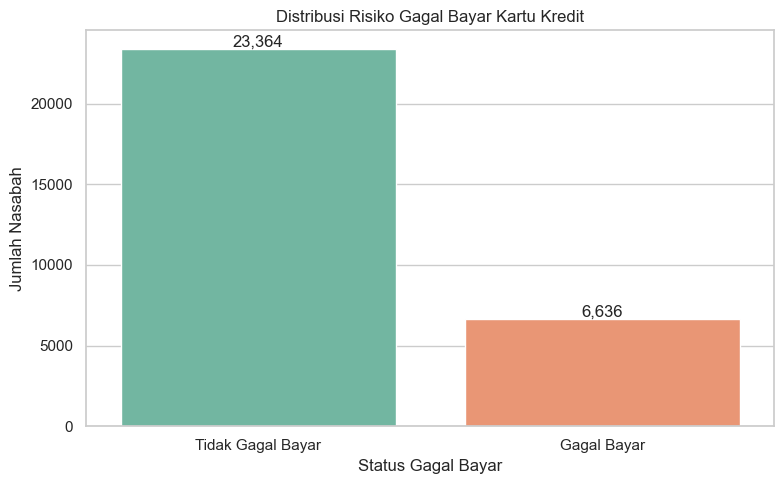

In [8]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x=target,
    hue=target,
    order=[0, 1],
    palette="Set2",
    legend=False
)
ax.set_title("Distribusi Risiko Gagal Bayar Kartu Kredit")
ax.set_xlabel("Status Gagal Bayar")
ax.set_ylabel("Jumlah Nasabah")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Tidak Gagal Bayar", "Gagal Bayar"])

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height):,}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 9. Distribusi usia nasabah

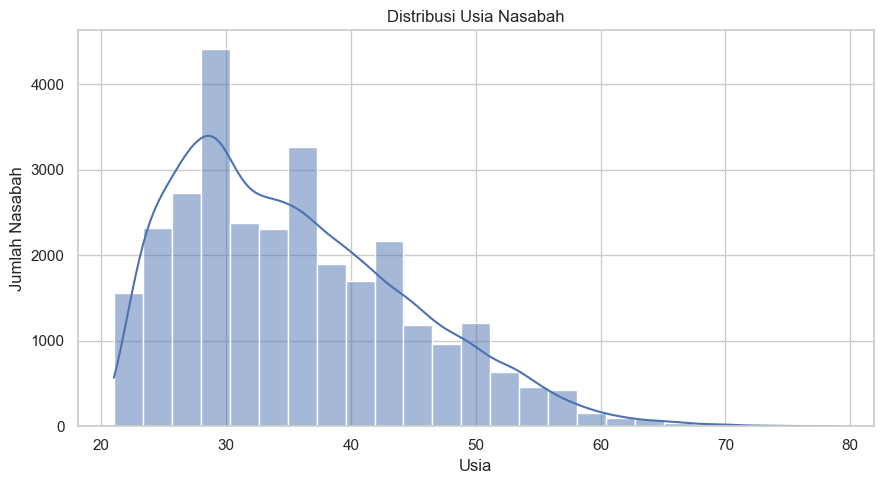

In [9]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="AGE", bins=25, kde=True)
plt.title("Distribusi Usia Nasabah")
plt.xlabel("Usia")
plt.ylabel("Jumlah Nasabah")
plt.tight_layout()
plt.show()

## 10. Distribusi batas kredit

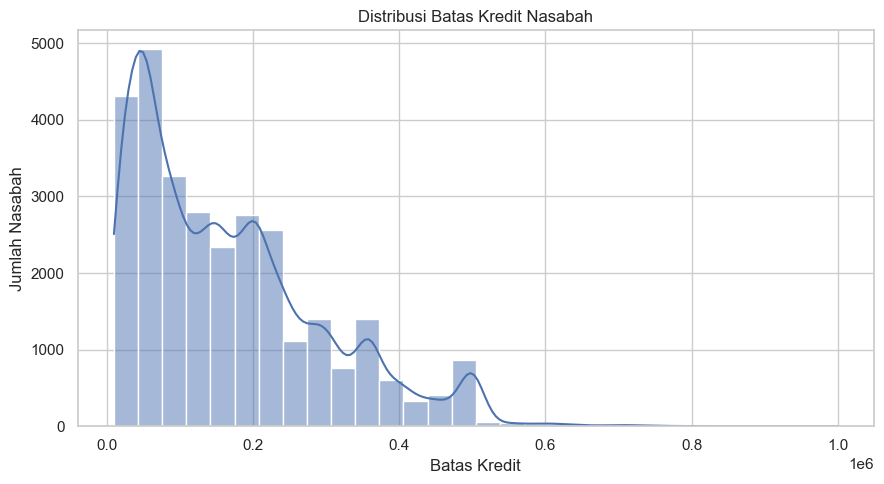

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="LIMIT_BAL", bins=30, kde=True)
plt.title("Distribusi Batas Kredit Nasabah")
plt.xlabel("Batas Kredit")
plt.ylabel("Jumlah Nasabah")
plt.tight_layout()
plt.show()

## 11. Status pembayaran bulan terakhir

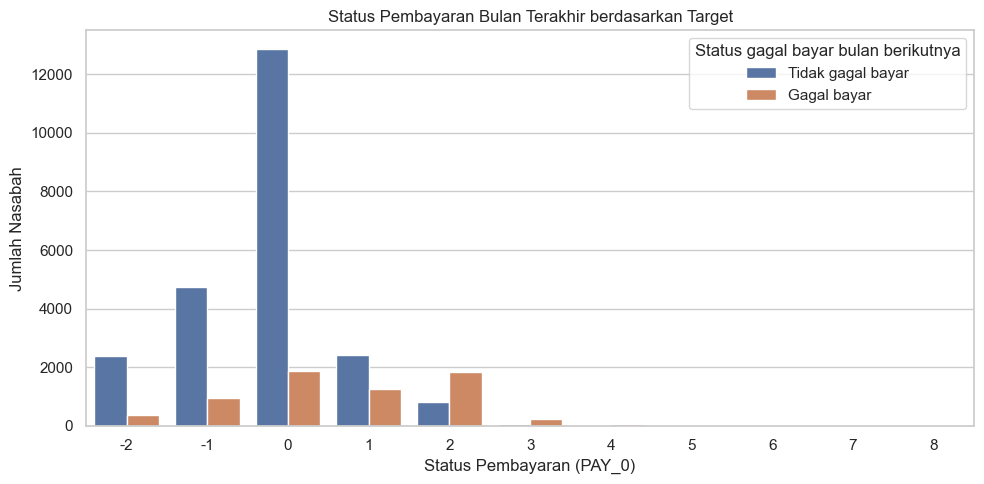

In [11]:
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="PAY_0",
    hue=target,
    order=sorted(df["PAY_0"].dropna().unique())
)
plt.title("Status Pembayaran Bulan Terakhir berdasarkan Target")
plt.xlabel("Status Pembayaran (PAY_0)")
plt.ylabel("Jumlah Nasabah")
plt.legend(
    title="Status gagal bayar bulan berikutnya",
    labels=["Tidak gagal bayar", "Gagal bayar"]
)
plt.tight_layout()
plt.show()

## 12. Korelasi fitur pilihan dan target

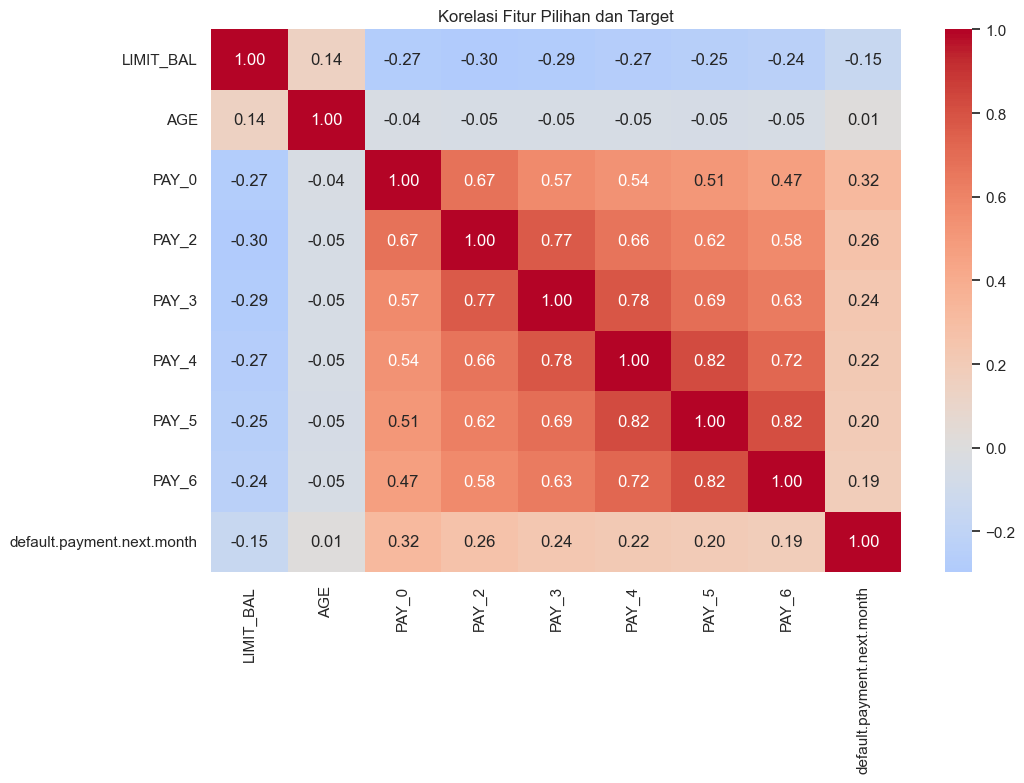

In [12]:
fitur_korelasi = [
    "LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6", target
]

plt.figure(figsize=(11, 8))
sns.heatmap(
    df[fitur_korelasi].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Korelasi Fitur Pilihan dan Target")
plt.tight_layout()
plt.show()

## 13. Ringkasan EDA

Jalankan sel berikut untuk melihat ringkasan otomatis. Gunakan angka hasil notebook untuk menuliskan laporan, bukan hanya menyalin kesimpulan umum.

In [13]:
jumlah_default = int((df[target] == 1).sum())
jumlah_non_default = int((df[target] == 0).sum())
persen_default = df[target].mean() * 100

print(f"Total observasi: {len(df):,}")
print(f"Jumlah kolom awal: {df.shape[1]}")
print(f"Jumlah nilai kosong: {int(df.isnull().sum().sum())}")
print(f"Jumlah baris duplikat: {int(df.duplicated().sum())}")
print(f"Tidak gagal bayar (0): {jumlah_non_default:,} ({100-persen_default:.2f}%)")
print(f"Gagal bayar (1): {jumlah_default:,} ({persen_default:.2f}%)")

if persen_default < 40:
    print("\nCatatan: kelas gagal bayar lebih sedikit daripada kelas tidak gagal bayar.")
    print("Pertimbangkan evaluasi Recall, F1-score, ROC-AUC, dan penanganan class imbalance pada tahap pemodelan.")

Total observasi: 30,000
Jumlah kolom awal: 25
Jumlah nilai kosong: 0
Jumlah baris duplikat: 0
Tidak gagal bayar (0): 23,364 (77.88%)
Gagal bayar (1): 6,636 (22.12%)

Catatan: kelas gagal bayar lebih sedikit daripada kelas tidak gagal bayar.
Pertimbangkan evaluasi Recall, F1-score, ROC-AUC, dan penanganan class imbalance pada tahap pemodelan.


## 14. Kesimpulan awal

Lengkapi setelah semua sel dijalankan:
1. Berapa jumlah observasi dan fitur dalam dataset?
2. Apakah ada nilai kosong atau data duplikat?
3. Berapa persentase nasabah yang gagal bayar?
4. Apa yang terlihat dari distribusi usia, batas kredit, dan status pembayaran?
5. Mengapa ketidakseimbangan kelas perlu diperhatikan saat melatih model?

**Langkah berikutnya:** preprocessing, pembagian data train/test, encoding fitur kategorikal, scaling, lalu pelatihan dan evaluasi Logistic Regression.